# Derivatives, Partial Derivatives, and the Chain Rule

**AI Mathematics · 2. Calculus**

Learn the derivatives that explain how model outputs and losses change when inputs or parameters change.

> The emphasis is on short, reusable examples rather than long projects. Code examples use Python and NumPy unless noted otherwise.

## Learning objectives
- Calculate derivatives and partial derivatives.
- Use the chain rule for composite functions.
- Estimate derivatives with finite differences.

In [1]:
import numpy as np

## 1. Derivative as local sensitivity
For a scalar function, the derivative is the local rate of change. In machine learning, it describes how a loss changes when a parameter changes. The derivative is a local quantity, not a guarantee of global behavior.

In [2]:
def f(x):
    return x**2 + 3*x

x = 2.0
analytic = 2*x + 3
eps = 1e-5
finite_difference = (f(x + eps) - f(x - eps)) / (2*eps)
print("analytic:", analytic)
print("central difference:", finite_difference)

analytic: 7.0
central difference: 7.0000000000902665


## 2. Partial and total derivatives
For \(f(x,y)\), a partial derivative changes one variable while holding the other fixed. A total derivative accounts for dependence along a path such as \(y=y(x)\). For \(f(x,y)=x^2y\), \(\partial f/\partial x=2xy\), and if \(y=y(x)\), then \(df/dx=2xy+x^2dy/dx\).

In [3]:
x, y = 2.0, 3.0
df_dx_partial = 2*x*y
df_dy_partial = x**2
print("partial df/dx:", df_dx_partial)
print("partial df/dy:", df_dy_partial)

# Along y = x + 1, dy/dx = 1
df_dx_total = 2*x*y + x**2
print("total derivative along y=x+1:", df_dx_total)

partial df/dx: 12.0
partial df/dy: 4.0
total derivative along y=x+1: 16.0


## 3. Chain rule
If \(z=g(x)\) and \(y=f(z)\), then \(dy/dx=(dy/dz)(dz/dx)\). Deep-network backpropagation repeatedly applies this rule from the loss back through each operation.

In [4]:
x = 2.0
z = x**2        # g(x)
y = 3*z + 1     # f(z)
dz_dx = 2*x
dy_dz = 3.0
dy_dx = dy_dz * dz_dx
print("y:", y)
print("chain-rule derivative:", dy_dx)

# Equivalent expression is y = 3*x**2 + 1, derivative 6*x.
print("direct derivative:", 6*x)

y: 13.0
chain-rule derivative: 12.0
direct derivative: 12.0


## 4. Directional derivatives
For differentiable \(f:\mathbb{R}^n\to\mathbb{R}\), the directional derivative in unit direction \(u\) is \(D_u f(x)=\nabla f(x)^T u\). The gradient points in the direction of steepest local increase under the Euclidean norm.

In [5]:
def f2(v):
    x, y = v
    return x**2 + 2*y**2

point = np.array([1.0, 2.0])
grad = np.array([2*point[0], 4*point[1]])
u = np.array([1.0, 1.0])
u = u / np.linalg.norm(u)
print("gradient:", grad)
print("directional derivative:", grad @ u)

gradient: [2. 8.]
directional derivative: 7.071067811865475


## 5. When finite differences can mislead
Central differences have truncation error that decreases with step size, but extremely tiny steps amplify floating-point cancellation. Choose a reasonable scale for `eps`, and prefer automatic differentiation for gradients in modern ML frameworks.

In [6]:
def central_difference(func, x, eps=1e-5):
    return (func(x + eps) - func(x - eps)) / (2*eps)

for step in [1e-1, 1e-3, 1e-5, 1e-8]:
    estimate = central_difference(lambda t: np.sin(t), 0.7, eps=step)
    print(step, estimate, "error:", abs(estimate - np.cos(0.7)))

0.1 0.7635680875224365 error: 0.00127409976205195
0.001 0.7648420598108108 error: 1.2747367772458773e-07
1e-05 0.764842187267467 error: 1.702149532434305e-11
1e-08 0.7648421895822821 error: 2.297793622041411e-09


### Choosing the right Python tool

- **NumPy** handles arrays, vectorized arithmetic, linear algebra, random sampling, and numerical operations.
- **pandas** is useful for named columns, tabular summaries, and experiment logs.
- **Matplotlib** gives low-level control over vector arrows, geometry, contour plots, and custom figures.
- **Seaborn** is built on Matplotlib and makes statistical plots such as heatmaps, distributions, and grouped comparisons quick to create.

Not every mathematical idea needs all four libraries. The extra examples use each tool where it clarifies the concept. Plots are diagnostic aids: always inspect axes, units, assumptions, and sample size.

## Visual lab: a derivative is a local slope

The derivative at a point is the slope of the tangent line. A tangent-line approximation is accurate near the expansion point and usually becomes less accurate farther away. The visualization compares the original function with its local linear approximation.

06_derivatives_and_chain_rule.ipynb:cell15:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


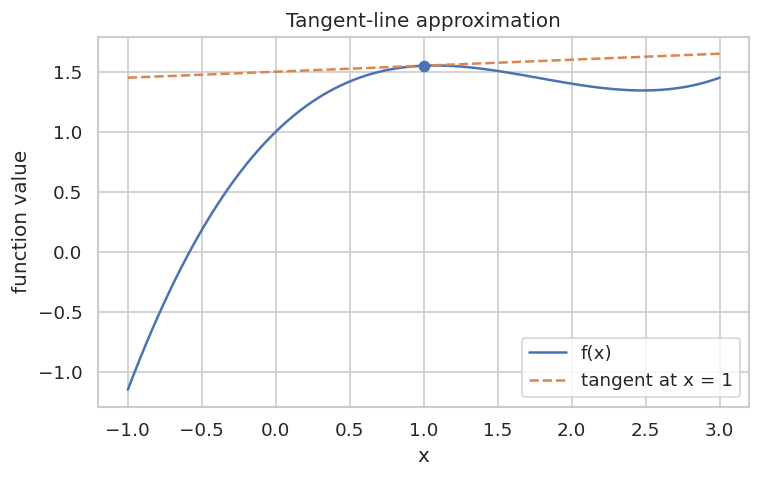

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
sns.set_theme(style="whitegrid")
def viz_deriv_f(t):
    return 0.15*t**3 - 0.8*t**2 + 1.2*t + 1

def viz_deriv_df(t):
    return 0.45*t**2 - 1.6*t + 1.2
viz_deriv_x0 = 1.0
viz_deriv_x = np.linspace(-1, 3, 300)
viz_deriv_tangent = viz_deriv_f(viz_deriv_x0) + viz_deriv_df(viz_deriv_x0)*(viz_deriv_x-viz_deriv_x0)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(viz_deriv_x, viz_deriv_f(viz_deriv_x), label="f(x)")
ax.plot(viz_deriv_x, viz_deriv_tangent, "--", label="tangent at x = 1")
ax.scatter([viz_deriv_x0], [viz_deriv_f(viz_deriv_x0)], zorder=3)
ax.set_xlabel("x"); ax.set_ylabel("function value"); ax.legend(); ax.set_title("Tangent-line approximation"); plt.show()

### Check a derivative numerically

A finite difference estimates a derivative by comparing nearby function values. A smaller step is not always better: subtraction and floating-point rounding can dominate when the step is extremely small. Compare the forward-difference estimate with the analytical derivative across several step sizes.

analytical derivative: 0.04999999999999982


06_derivatives_and_chain_rule.ipynb:cell17:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


,step h,forward error,central error
0,1.000000e-01,3.350000e-02,1.500000e-03
1,1.000000e-02,3.485000e-03,1.500000e-05
2,1.000000e-03,3.498500e-04,1.500000e-07
3,1.000000e-04,3.499850e-05,1.499000e-09
4,1.000000e-05,3.499971e-06,1.800000e-11
5,1.000000e-06,3.502460e-07,8.200000e-11
6,1.000000e-07,3.361100e-08,8.060000e-10
7,1.000000e-08,4.137000e-09,4.137000e-09
8,1.000000e-09,4.137000e-09,4.137000e-09
9,1.000000e-10,4.137000e-09,4.137000e-09


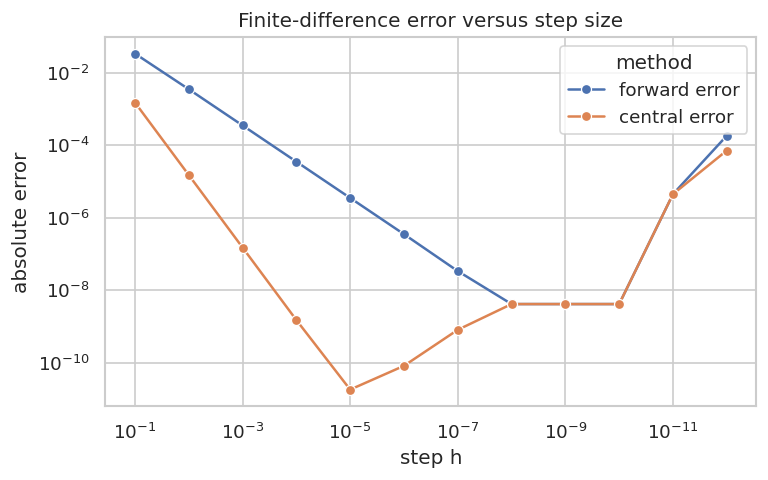

In [8]:
viz_deriv_hs = np.logspace(-1, -12, 12)
viz_deriv_forward = (viz_deriv_f(viz_deriv_x0 + viz_deriv_hs) - viz_deriv_f(viz_deriv_x0)) / viz_deriv_hs
viz_deriv_central = (viz_deriv_f(viz_deriv_x0 + viz_deriv_hs) - viz_deriv_f(viz_deriv_x0 - viz_deriv_hs)) / (2*viz_deriv_hs)
viz_deriv_exact = viz_deriv_df(viz_deriv_x0)
viz_deriv_df_table = pd.DataFrame({"step h": viz_deriv_hs, "forward error": np.abs(viz_deriv_forward-viz_deriv_exact), "central error": np.abs(viz_deriv_central-viz_deriv_exact)})
display(viz_deriv_df_table.round(12))
fig, ax = plt.subplots(figsize=(7, 4))
sns.lineplot(data=viz_deriv_df_table.melt(id_vars="step h", var_name="method", value_name="absolute error"), x="step h", y="absolute error", hue="method", marker="o", ax=ax)
ax.set_xscale("log"); ax.set_yscale("log"); ax.invert_xaxis(); ax.set_title("Finite-difference error versus step size"); plt.show()
print("analytical derivative:", viz_deriv_exact)

## Practice exercises
Try each exercise before looking at the suggested solution. These are intentionally small so you can change values and observe how the result changes.

### Exercise 1
Exercise 1: Differentiate f(x) = x^3 - 2x at x = 2.

In [9]:
x = 2.0
print(3*x**2 - 2)

10.0


### Exercise 2
Exercise 2: Estimate the derivative of exp(x) at x = 0 using a central difference.

In [10]:
eps = 1e-5
print((np.exp(eps) - np.exp(-eps)) / (2*eps))

1.0000000000121023


## Key takeaways
- The derivative is local sensitivity; partial derivatives change one coordinate at a time.
- The chain rule is the mathematical basis of backpropagation.
- Finite differences are useful for checks, but step size and floating-point precision matter.

**Next step:** Change an input, check the shapes or assumptions, and rerun the relevant cell. That habit is central to mathematical programming.